# LAB 04 — Text Classification (IMDb Sentiment)

**Chủ đề:** From Text Representation to Supervised NLP
**Dataset:** [IMDb](https://huggingface.co/datasets/stanfordnlp/imdb) — sentiment `positive` / `negative`

| Notebook | Mục trong đề | Nội dung |
|---|---|---|
| 0 | — | Setup |
| 1 | §11 | Experiment 1 — Dataset inspection |
| 2 | §12 | Train / Validation / Test split (pipeline đúng) |
| 3 | §12 | Data leakage |
| 4 | §13, §14 | Core implementation + Experiment 2 — Baseline TF-IDF + LR |
| 5 | §15, §16 | Experiment 3 — Representation comparison |
| 6 | §17 | Experiment 4 — Word order |
| 7 | §18 | Experiment 5 — n-gram features |
| 8 | §10 (phần thêm) | Kiểm chứng Prediction 3, 4, 5 |
| 9 | §19, §20 | Evaluation & Confusion matrix |
| 10 | §21 | Error analysis |
| 11 | §22 | Inspect model weights |
| 12 | §26 | Tổng hợp → `results.csv` |

Phần của đề **không** nằm trong notebook: §1–4 theory recap · §5, §10 → `prediction.md` · §6–9 → `calculations.md` · §21 phân tích → `error_analysis.md` · §23 Application = chọn IMDb (Option A) · §24 AI policy → `README.md` · §25 vấn đáp.

Các ô **✍️ Tự trả lời** là phần diễn giải / phân tích sinh viên tự viết (theo AI policy, mục 24).

## 0. Setup

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

import preprocessing as pp

SEED = pp.SEED
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

C_GRID = [0.01, 0.1, 1, 10, 100]     # chọn C trên validation
N_WORKERS = min(8, os.cpu_count() or 1)
RESULTS = {}                          # (experiment, representation, classifier, features) -> metrics

## 1. Experiment 1 — Dataset inspection (Đề §11)

Chưa train model ở bước này. Kiểm tra: số samples, số classes, class distribution,
document length, duplicate documents, missing text, missing labels.

In [2]:
raw_train, raw_test = pp.load_imdb()
print(f"Train: {len(raw_train):,} samples | Test: {len(raw_test):,} samples")
raw_train.head()

Train: 25,000 samples | Test: 25,000 samples


,text,label
0,I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first...,0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are ...",0
2,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no coge...,0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />Th...",0
4,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee so...",0


### 1.1 Số classes & class distribution

Số classes: 2 -> {0: 'negative', 1: 'positive'}


train              test           
          Count Percentage  Count Percentage
label                                       
negative  12500       50.0  12500       50.0
positive  12500       50.0  12500       50.0

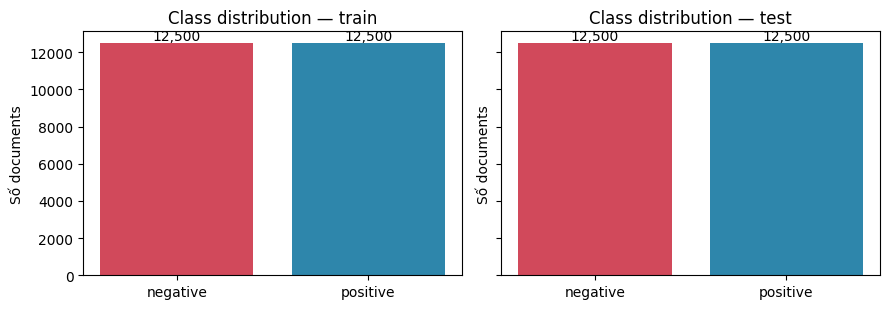

In [3]:
print("Số classes:", raw_train["label"].nunique(), "->", {k: v for k, v in pp.LABEL_NAMES.items()})
display(pd.concat({"train": pp.class_distribution(raw_train["label"]),
                   "test": pp.class_distribution(raw_test["label"])}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, df) in zip(axes, [("train", raw_train), ("test", raw_test)]):
    counts = df["label"].map(pp.LABEL_NAMES).value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=["#d1495b", "#2e86ab"])
    for x, v in enumerate(counts.values):
        ax.text(x, v, f"{v:,}", ha="center", va="bottom")
    ax.set_title(f"Class distribution — {name}")
    ax.set_ylabel("Số documents")
plt.tight_layout()
plt.show()

### 1.2 Missing text / missing labels

In [4]:
def missing_report(df):
    text = df["text"]
    return pd.Series({
        "missing text (NaN)": text.isna().sum(),
        "text rỗng / chỉ khoảng trắng": (text.fillna("").str.strip() == "").sum(),
        "missing label (NaN)": df["label"].isna().sum(),
        "label ngoài {0, 1}": (~df["label"].isin([0, 1])).sum(),
    })

pd.DataFrame({"train": missing_report(raw_train), "test": missing_report(raw_test)})

,train,test
missing text (NaN),0,0
text rỗng / chỉ khoảng trắng,0,0
missing label (NaN),0,0
"label ngoài {0, 1}",0,0


### 1.3 Document length (số tokens sau `pp.tokenize`)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,12500.0,230.6,166.2,10.0,128.0,174.0,278.0,1522.0
positive,12500.0,236.6,180.1,12.0,126.0,174.0,290.0,2473.0


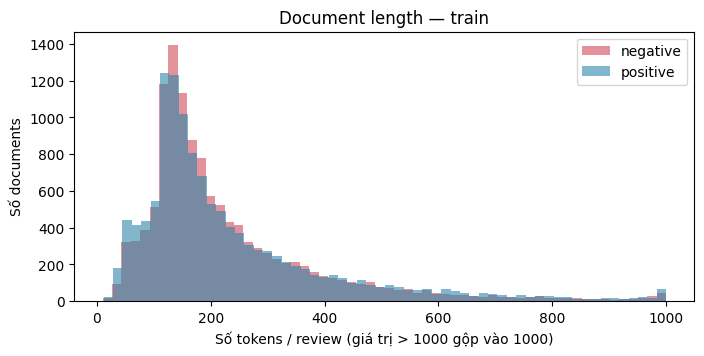

In [5]:
for df in (raw_train, raw_test):
    df["n_tokens"] = df["text"].map(lambda t: len(pp.tokenize(t)))

display(raw_train.groupby(raw_train["label"].map(pp.LABEL_NAMES))["n_tokens"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
for lbl, color in [(0, "#d1495b"), (1, "#2e86ab")]:
    ax.hist(raw_train.loc[raw_train["label"] == lbl, "n_tokens"].clip(upper=1000),
            bins=60, alpha=0.6, color=color, label=pp.LABEL_NAMES[lbl])
ax.set_xlabel("Số tokens / review (giá trị > 1000 gộp vào 1000)")
ax.set_ylabel("Số documents")
ax.set_title("Document length — train")
ax.legend()
plt.show()

### 1.4 Duplicate documents

So sánh sau khi chuẩn hóa nhẹ (`pp.clean_text`: lowercase, bỏ `<br />`, chuẩn hóa khoảng trắng).
Review xuất hiện ở **cả train và test** là một dạng leakage cần xử lý trước khi split.

In [6]:
for df in (raw_train, raw_test):
    df["norm"] = df["text"].map(pp.clean_text)

train_test_overlap = set(raw_train["norm"]) & set(raw_test["norm"])
pd.Series({
    "duplicate trong train": raw_train["norm"].duplicated().sum(),
    "duplicate trong test": raw_test["norm"].duplicated().sum(),
    "review có ở cả train và test": len(train_test_overlap),
    "nhóm duplicate trong train có label mâu thuẫn": raw_train.groupby("norm")["label"].nunique().gt(1).sum(),
}).to_frame("count")

,count
duplicate trong train,98
duplicate trong test,201
review có ở cả train và test,123
nhóm duplicate trong train có label mâu thuẫn,0


In [7]:
# Ví dụ một review bị lặp trong train
dup_example = raw_train.loc[raw_train["norm"].duplicated(keep=False)].sort_values("norm").head(2)
dup_example[["text", "label"]]

,text,label
934,"'Dead Letter Office' is a low-budget film about a couple of employees of the Australian postal service, struggling t...",0
4217,"'Dead Letter Office' is a low-budget film about a couple of employees of the Australian postal service, struggling t...",0


> ✍️ **Tự trả lời:** Dataset có imbalance không? (dựa vào bảng và biểu đồ class distribution)
>
> Không, bộ dữ liệu này rất cân bằng

## 2. Train / Validation / Test split (Đề §12)

- **Test:** giữ nguyên test chuẩn của IMDb (25k) — chỉ dùng để báo cáo kết quả cuối.
- **Train gốc:** bỏ nhóm duplicate có label mâu thuẫn, bỏ duplicate, bỏ review trùng với test;
  sau đó chia **80% train / 20% validation**, stratified theo label.
- **Validation:** dùng để chọn siêu tham số `C`. Không chọn bất cứ thứ gì dựa trên test.

In [8]:
conflicting = raw_train.groupby("norm")["label"].transform("nunique") > 1
clean_train = (raw_train[~conflicting]
               .drop_duplicates("norm")
               .loc[lambda d: ~d["norm"].isin(train_test_overlap)]
               .reset_index(drop=True))
print(f"Train gốc: {len(raw_train):,} -> sau khi làm sạch: {len(clean_train):,}")

train_df, val_df = pp.split_train_val(clean_train, val_size=0.2)
test_df = raw_test.reset_index(drop=True)

assert not set(train_df["norm"]) & set(val_df["norm"]), "train/val bị trùng"
assert not set(train_df["norm"]) & set(test_df["norm"]), "train/test bị trùng"

X_train, y_train = train_df["text"], train_df["label"].to_numpy()
X_val, y_val = val_df["text"], val_df["label"].to_numpy()
X_test, y_test = test_df["text"], test_df["label"].to_numpy()

pd.concat({name: pp.class_distribution(y)
           for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]}, axis=1)

Train gốc: 25,000 -> sau khi làm sạch: 24,779


train            validation              test           
         Count Percentage      Count Percentage  Count Percentage
positive  9954      50.21       2489      50.22  12500       50.0
negative  9869      49.79       2467      49.78  12500       50.0

## 3. Data leakage (Đề §12)

| Pipeline đúng | Pipeline sai |
|---|---|
| Split → **fit TF-IDF trên TRAIN** → transform val/test → train model | **Fit TF-IDF trên toàn bộ dataset** → split → train model |

Ô dưới fit TF-IDF theo cả hai cách rồi so sánh vocabulary và IDF.

In [9]:
vec_ok = TfidfVectorizer(**pp.tfidf_params()).fit(X_train)                                # ĐÚNG
vec_leak = TfidfVectorizer(**pp.tfidf_params()).fit(pd.concat([X_train, X_val, X_test]))  # SAI

vocab_ok, vocab_leak = set(vec_ok.vocabulary_), set(vec_leak.vocabulary_)
leaked_terms = sorted(vocab_leak - vocab_ok)
print(f"Vocabulary — fit trên train        : {len(vocab_ok):,}")
print(f"Vocabulary — fit trên toàn dataset : {len(vocab_leak):,}")
print(f"Terms có được nhờ nhìn thấy val/test: {len(leaked_terms):,}")
print("Ví dụ:", [str(t) for t in np.random.default_rng(SEED).choice(leaked_terms, 15, replace=False)])

Vocabulary — fit trên train        : 43,077
Vocabulary — fit trên toàn dataset : 64,159
Terms có được nhờ nhìn thấy val/test: 21,082
Ví dụ: ['bergan', 'bijou', 'parlays', 'sadomania', 'crapy', 'rapier', 'bekim', 'reproducing', 'indignantly', 'superficialities', 'imperceptibly', "louden's", 'scheffer', "profession's", 'windbreaker']


In [10]:
common = sorted(vocab_ok & vocab_leak)
idf_ok = pd.Series(vec_ok.idf_[[vec_ok.vocabulary_[t] for t in common]], index=common)
idf_leak = pd.Series(vec_leak.idf_[[vec_leak.vocabulary_[t] for t in common]], index=common)
idf_diff = idf_leak - idf_ok
print(f"Số term có IDF thay đổi: {(idf_diff.abs() > 1e-9).sum():,} / {len(common):,}")
pd.DataFrame({"idf (fit train)": idf_ok, "idf (fit toàn bộ)": idf_leak, "chênh lệch": idf_diff}) \
  .loc[idf_diff.abs().sort_values(ascending=False).index[:10]].round(3)

Số term có IDF thay đổi: 43,077 / 43,077


,idf (fit train),idf (fit toàn bộ),chênh lệch
zellweger,9.508,7.903,-1.605
julianne,9.508,7.903,-1.605
wynorski,9.796,8.204,-1.592
bullock,8.815,7.251,-1.564
estevez,9.508,7.987,-1.522
minnie,9.508,7.987,-1.522
nero,9.796,8.289,-1.507
nikki,9.508,8.078,-1.431
farley,9.285,7.864,-1.421
vito,9.796,8.381,-1.415


In [11]:
# Cùng một classifier (LR, C=1) trên hai representation
def quick_eval(vec):
    clf = LogisticRegression(C=1.0, solver="liblinear").fit(vec.transform(X_train), y_train)
    pred = clf.predict(vec.transform(X_test))
    return {"test accuracy": accuracy_score(y_test, pred), "test F1": f1_score(y_test, pred)}

pd.DataFrame({"fit TF-IDF trên train (đúng)": quick_eval(vec_ok),
              "fit TF-IDF trên toàn bộ (leak)": quick_eval(vec_leak)}).T.round(4)

,test accuracy,test F1
fit TF-IDF trên train (đúng),0.8837,0.8842
fit TF-IDF trên toàn bộ (leak),0.8834,0.8840


> ✍️ **Tự trả lời:** Vì sao fit TF-IDF trên toàn bộ dataset trước khi split là data leakage?
>
> Vì lúc này trong thông tin thống kê mô tả (có sử dụng trong TF-IDF) đã chứa cả thông tin của tập test,vì thế model sẽ học được các thông tin này, dẫn đến đánh giá sai về khả năng tổng quát hóa của model.

## 4. Core implementation + Experiment 2 — Baseline TF-IDF + Logistic Regression (Đề §13, §14)

```
Raw text → TF-IDF → Classifier → Prediction → Evaluation
```

- Positive class = `positive` (label 1) khi tính precision / recall / F1.
- `train_time_s` = thời gian fit representation trên train + fit classifier với `C` tốt nhất.
- Mọi representation chỉ được `fit` trên **train**; val/test chỉ `transform`.

In [12]:
def evaluate(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def fit_select_C(make_clf, Xtr, Xva, c_grid):
    """Train một model cho mỗi C trên TRAIN, giữ model có F1 cao nhất trên VALIDATION."""
    best = None
    for C in c_grid:
        t0 = time.perf_counter()
        clf = make_clf(C).fit(Xtr, y_train)
        fit_time = time.perf_counter() - t0
        val_f1 = f1_score(y_val, clf.predict(Xva))
        if best is None or val_f1 > best["val_f1"]:
            best = {"clf": clf, "C": C, "val_f1": val_f1, "fit_time": fit_time}
    return best


def run_experiment(experiment, representation, classifier, features,
                   make_vectorizer, make_clf, c_grid=C_GRID):
    """fit representation trên train -> transform val/test -> chọn C trên val -> đánh giá trên test."""
    t0 = time.perf_counter()
    vec = make_vectorizer()
    Xtr = vec.fit_transform(X_train)
    rep_time = time.perf_counter() - t0
    Xva, Xte = vec.transform(X_val), vec.transform(X_test)

    best = fit_select_C(make_clf, Xtr, Xva, c_grid)
    y_pred = best["clf"].predict(Xte)
    vocab = len(vec.vocabulary_) if hasattr(vec, "vocabulary_") else len(vec.wv)
    row = {"experiment": experiment, "representation": representation, "classifier": classifier,
           "features": features, "vocab_size": vocab, "n_dims": Xtr.shape[1], "best_C": best["C"],
           "train_time_s": rep_time + best["fit_time"], "val_f1": best["val_f1"],
           **evaluate(y_test, y_pred)}
    RESULTS[(experiment, representation, classifier, features)] = row
    return {"vec": vec, "clf": best["clf"], "Xte": Xte, "y_pred": y_pred, "row": row}


def show(*runs):
    cols = ["representation", "classifier", "features", "vocab_size", "best_C",
            "train_time_s", "accuracy", "precision", "recall", "f1"]
    return pd.DataFrame([r["row"] for r in runs])[cols].round(4)


def feature_names(run):
    if "names" not in run:
        run["names"] = run["vec"].get_feature_names_out()
    return run["names"]


def contributions(run, text):
    """Đóng góp w_j * x_j của từng feature vào z = w^T x + b (TF-IDF + model tuyến tính)."""
    x = run["vec"].transform([text])
    w = run["clf"].coef_.ravel()
    return (pd.DataFrame({"feature": feature_names(run)[x.indices], "tfidf": x.data,
                          "weight": w[x.indices], "contribution": x.data * w[x.indices]})
              .sort_values("contribution", key=abs, ascending=False, ignore_index=True))


def weight_of(run, terms):
    vocab, w = run["vec"].vocabulary_, run["clf"].coef_.ravel()
    return pd.Series({t: w[vocab[t]] if t in vocab else np.nan for t in terms})


make_lr = lambda C: LogisticRegression(C=C, solver="liblinear", max_iter=1000)

In [13]:
run_A = run_experiment("Exp2 baseline / Exp3-A / Exp5 unigram", "TF-IDF", "Logistic Regression", "unigram",
                       lambda: TfidfVectorizer(**pp.tfidf_params()), make_lr)
show(run_A)

,representation,classifier,features,vocab_size,best_C,train_time_s,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,unigram,43077,10,3.4913,0.8798,0.8825,0.8762,0.8793


**Kiểm tra lại công thức** $z = \mathbf{w}^\top \mathbf{x} + b$, $P(y=1 \mid x) = \sigma(z)$
trên một review của test — tính tay bằng `coef_`, `intercept_` rồi so với `predict_proba`.

In [14]:
clf_A = run_A["clf"]
x = run_A["Xte"][0]
z = (x @ clf_A.coef_.ravel()).item() + clf_A.intercept_[0]
print(f"Số features khác 0 trong x: {x.nnz} / {x.shape[1]:,}")
print(f"z = w^T x + b       = {z:.4f}")
print(f"sigmoid(z)          = {1 / (1 + np.exp(-z)):.6f}")
print(f"predict_proba[:, 1] = {clf_A.predict_proba(x)[0, 1]:.6f}")

Số features khác 0 trong x: 156 / 43,077
z = w^T x + b       = -4.4930
sigmoid(z)          = 0.011063
predict_proba[:, 1] = 0.011063


## 5. Experiment 3 — Representation comparison (Đề §15, §16)

| Model | Representation | Classifier |
|---|---|---|
| A | TF-IDF (unigram) | Logistic Regression — đã chạy ở mục 4 |
| B | Average Word2Vec | Logistic Regression |
| C | TF-IDF (unigram) | Linear SVM |

Word2Vec được train **chỉ trên train split** (skip-gram, 100 chiều, window 5, min_count 2, 10 epochs),
cùng tokenizer với TF-IDF. Vector trung bình được chuẩn hóa bằng `StandardScaler` (fit trên train) trước LR.
Gensim train đa luồng nên kết quả Model B có thể lệch nhẹ giữa các lần chạy.

In [15]:
make_lr_scaled = lambda C: make_pipeline(StandardScaler(),
                                         LogisticRegression(C=C, solver="liblinear", max_iter=1000))
run_B = run_experiment("Exp3-B", "Avg Word2Vec", "Logistic Regression", "skip-gram d=100",
                       lambda: pp.MeanEmbeddingVectorizer(workers=N_WORKERS), make_lr_scaled)
w2v = run_B["vec"]
print(f"Word2Vec vocabulary: {len(w2v.wv):,} | OOV rate trên test: {w2v.oov_rate(X_test):.4f}")
for word in ["good", "not", "boring"]:
    print(f"most_similar({word!r}):", [w for w, _ in w2v.wv.most_similar(word, topn=8)])
show(run_B)

Word2Vec vocabulary: 45,311 | OOV rate trên test: 0.0157
most_similar('good'): ['decent', 'great', 'bad', 'workable', 'nice', 'passable', 'fine', 'ok']
most_similar('not'): ['legitimately', 'parinda', "isn't", "was'nt", "wasn't", 'neither', 'butthead', 'revile']
most_similar('boring'): ['dull', 'tedious', 'predictable', 'pointless', 'intolerably', 'unoriginal', 'uninteresting', 'tiresome']


,representation,classifier,features,vocab_size,best_C,train_time_s,accuracy,precision,recall,f1
0,Avg Word2Vec,Logistic Regression,skip-gram d=100,45311,1,49.0902,0.8582,0.8626,0.8522,0.8574


In [16]:
run_C = run_experiment("Exp3-C", "TF-IDF", "Linear SVM", "unigram",
                       lambda: TfidfVectorizer(**pp.tfidf_params()),
                       lambda C: LinearSVC(C=C, max_iter=5000))
show(run_A, run_B, run_C)

,representation,classifier,features,vocab_size,best_C,train_time_s,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,unigram,43077,10,3.4913,0.8798,0.8825,0.8762,0.8793
1,Avg Word2Vec,Logistic Regression,skip-gram d=100,45311,1,49.0902,0.8582,0.8626,0.8522,0.8574
2,TF-IDF,Linear SVM,unigram,43077,1,3.2257,0.8770,0.8818,0.8706,0.8762


> ✍️ **Tự trả lời:** Tại sao hai representation (TF-IDF vs Average Word2Vec) tạo ra kết quả khác nhau? 
>
> Vì rõ ràng 2 representation này khác nhau về cách biểu diễn dữ liệu. TF-IDF là sparse representation, dựa trên tần suất xuất hiện của từ trong văn bản, trong khi Average Word2Vec là dense representation, dựa trên ngữ nghĩa của từ. Cùng 1 classifier nhưng chạy trên 2 loại representation khác nhau thì không có gì đảm bảo kết quả sẽ giống nhau cả.

## 6. Experiment 4 — Word order (Đề §17)

S1 = `"this movie is good"`, S2 = `"this movie is not good"`.
Với average embeddings $\mathbf{v}(x) = \frac{1}{|x|}\sum_{w \in x} \mathbf{v}_w$
thì $\mathbf{v}(S_2) = \frac{4\,\mathbf{v}(S_1) + \mathbf{v}_{not}}{5}$ — kiểm tra bằng số:

In [17]:
S1, S2 = "this movie is good", "this movie is not good"
v1, v2 = w2v.transform([S1, S2])
print("v(S2) == (4·v(S1) + v_not) / 5 ?", np.allclose(v2, (4 * v1 + w2v.wv["not"]) / 5, atol=1e-6))


def cosine(a, b):
    a, b = np.asarray(a).ravel(), np.asarray(b).ravel()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


PAIRS = [
    ("this movie is good", "this movie is not good"),
    ("i like this movie", "i do not like this movie"),
    ("this movie is good not bad", "this movie is bad not good"),  # cùng bag-of-words, khác thứ tự
]
pd.DataFrame([{"S1": s1, "S2": s2,
               "cosine TF-IDF": cosine(run_A["vec"].transform([s1]).toarray(),
                                       run_A["vec"].transform([s2]).toarray()),
               "cosine Avg W2V": cosine(*w2v.transform([s1, s2]))}
              for s1, s2 in PAIRS]).round(4)

v(S2) == (4·v(S1) + v_not) / 5 ? True


,S1,S2,cosine TF-IDF,cosine Avg W2V
0,this movie is good,this movie is not good,0.8868,0.9770
1,i like this movie,i do not like this movie,0.7163,0.9575
2,this movie is good not bad,this movie is bad not good,1.0000,1.0000


In [18]:
def word_order_table(runs):
    rows = []
    for pair in PAIRS:
        for s in pair:
            row = {"sentence": s}
            for name, run in runs.items():
                row[f"P(pos) — {name}"] = run["clf"].predict_proba(run["vec"].transform([s]))[0, 1]
            rows.append(row)
    return pd.DataFrame(rows).round(4)


word_order_table({"TF-IDF uni + LR": run_A, "Avg W2V + LR": run_B})

,sentence,P(pos) — TF-IDF uni + LR,P(pos) — Avg W2V + LR
0,this movie is good,0.9208,0.9602
1,this movie is not good,0.5850,0.5960
2,i like this movie,0.4331,0.3504
3,i do not like this movie,0.0668,0.0165
4,this movie is good not bad,0.0036,0.0006
5,this movie is bad not good,0.0036,0.0006


In [19]:
# Đóng góp của từng từ vào z (Model A) cho S2 — "not" là một feature độc lập
print(f"intercept b = {run_A['clf'].intercept_[0]:.4f}")
contributions(run_A, S2).round(4)

intercept b = -0.1637


,feature,tfidf,weight,contribution
0,good,0.5936,3.4994,2.0774
1,not,0.4622,-3.9218,-1.8128
2,is,0.3379,1.8003,0.6084
3,this,0.3348,-1.0874,-0.3640
4,movie,0.4557,-0.0038,-0.0017


> ✍️ **Tự trả lời:** Average Word2Vec (và TF-IDF unigram) có hiểu được vai trò của "not" không? Vì sao?
>
> Dựa vào kết quả thực nghiệm, ta thấy rằng model đánh giá "not" là một từ quan trọng, contribute cao nhưng mặc định theo hướng tiêu cực chứ hoàn toàn không hiểu nghĩa của nó.  
> Điều này dễ hiểu vì cả TF-IDF và Average Word2Vec đều không lưu trữ thông tin về thứ tự từ mà chỉ dựa vào sự có mặt của các từ trong câu, nên chúng không thể phân biệt được "is good not bad" và "is bad not good".

## 7. Experiment 5 — n-gram features (Đề §18)

So sánh TF-IDF **unigram** với **unigram + bigram** (cùng Logistic Regression, cùng cách chọn `C`).
Với bigram, `"not good"`, `"very good"` trở thành các feature riêng.

In [20]:
run_bi = run_experiment("Exp5", "TF-IDF", "Logistic Regression", "uni + bigram",
                        lambda: TfidfVectorizer(**pp.tfidf_params(ngram_range=(1, 2))), make_lr)
pd.DataFrame([{"Features": name, "Vocabulary": r["row"]["vocab_size"], "F1": r["row"]["f1"],
               "Accuracy": r["row"]["accuracy"], "Training time (s)": r["row"]["train_time_s"]}
              for name, r in [("Unigram", run_A), ("Uni + Bigram", run_bi)]]).round(4)

,Features,Vocabulary,F1,Accuracy,Training time (s)
0,Unigram,43077,0.8793,0.8798,3.4913
1,Uni + Bigram,363647,0.9021,0.9020,9.8825


In [21]:
terms = ["good", "bad", "not", "like", "not good", "very good", "not bad", "not like", "not recommend"]
pd.DataFrame({"weight (unigram)": weight_of(run_A, terms),
              "weight (uni + bigram)": weight_of(run_bi, terms)}).round(4)

,weight (unigram),weight (uni + bigram)
good,3.4994,6.1552
bad,-9.8152,-17.8800
not,-3.9218,-5.0546
like,-0.4655,-0.7492
not good,NaN,-3.0709
very good,NaN,5.6871
not bad,NaN,2.7199
not like,NaN,3.6014
not recommend,NaN,-5.1330


In [22]:
# Câu ở Experiment 4 với model có bigram
word_order_table({"TF-IDF uni + LR": run_A, "TF-IDF uni+bi + LR": run_bi, "Avg W2V + LR": run_B})

,sentence,P(pos) — TF-IDF uni + LR,P(pos) — TF-IDF uni+bi + LR,P(pos) — Avg W2V + LR
0,this movie is good,0.9208,0.9440,0.9602
1,this movie is not good,0.5850,0.0194,0.5960
2,i like this movie,0.4331,0.9489,0.3504
3,i do not like this movie,0.0668,0.4619,0.0165
4,this movie is good not bad,0.0036,0.2232,0.0006
5,this movie is bad not good,0.0036,0.0030,0.0006


In [23]:
contributions(run_bi, S2).round(4)

,feature,tfidf,weight,contribution
0,not good,0.7385,-3.0709,-2.2679
1,is not,0.3578,-5.0042,-1.7906
2,good,0.2306,6.1552,1.4194
3,not,0.1796,-5.0546,-0.9076
4,this,0.1300,-5.5630,-0.7234
5,this movie,0.2421,2.9048,0.7032
6,movie is,0.3421,-1.1026,-0.3772
7,is,0.1313,1.9418,0.2549
8,movie,0.1770,-0.5622,-0.0995


> ✍️ **Tự trả lời:** Vì sao bigram có thể giúp classification nhưng đồng thời làm feature space lớn hơn?
>
> bigram bổ sung khả năng bắt được các cụm từ, từ đó gia tăng ý nghĩa cho representation. Và dĩ nhiên, việc bổ sung này đi kèm với việc tăng số lượng feature space (vì nó mở rộng corpus)

## 8. Kiểm chứng Prediction 3, 4, 5 (Đề §10 — phần thêm)

Chạy sau khi đã ghi prediction. Mỗi thí nghiệm chỉ thay đổi **một** yếu tố so với baseline (Model A).

### 8.1 Prediction 3 — Tăng vocabulary size có chắc chắn tăng accuracy?
Giữ nguyên `C` của baseline, chỉ thay `max_features` / `min_df`.

,representation,classifier,features,vocab_size,best_C,train_time_s,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,"unigram, max_features=500",500,10,2.8965,0.8427,0.8331,0.8571,0.8450
1,TF-IDF,Logistic Regression,"unigram, max_features=2000",2000,10,3.3055,0.8706,0.8664,0.8764,0.8713
2,TF-IDF,Logistic Regression,"unigram, max_features=10000",10000,10,3.7760,0.8763,0.8793,0.8722,0.8758
3,TF-IDF,Logistic Regression,"unigram, full vocab, min_df=2 (baseline)",43077,10,3.5633,0.8798,0.8825,0.8762,0.8793
4,TF-IDF,Logistic Regression,"unigram, full vocab, min_df=1",73542,10,3.4517,0.8804,0.8823,0.8778,0.8801


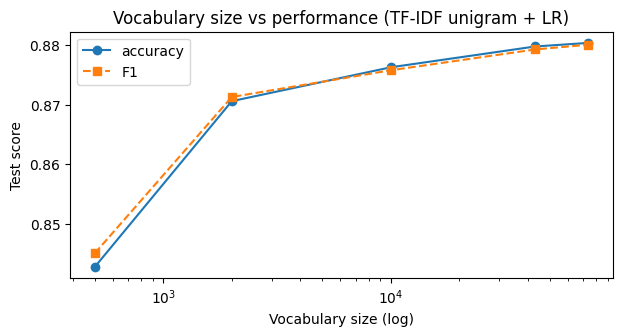

In [24]:
best_C_A = run_A["row"]["best_C"]
vocab_runs = {}
for label, overrides in [("max_features=500", dict(max_features=500)),
                         ("max_features=2000", dict(max_features=2000)),
                         ("max_features=10000", dict(max_features=10000)),
                         ("full vocab, min_df=2 (baseline)", dict()),
                         ("full vocab, min_df=1", dict(min_df=1))]:
    vocab_runs[label] = run_experiment("Pred3 vocab size", "TF-IDF", "Logistic Regression",
                                       f"unigram, {label}",
                                       lambda o=overrides: TfidfVectorizer(**pp.tfidf_params(**o)),
                                       make_lr, c_grid=[best_C_A])
vocab_table = show(*vocab_runs.values())
display(vocab_table)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(vocab_table["vocab_size"], vocab_table["accuracy"], "o-", label="accuracy")
ax.plot(vocab_table["vocab_size"], vocab_table["f1"], "s--", label="F1")
ax.set_xscale("log")
ax.set_xlabel("Vocabulary size (log)")
ax.set_ylabel("Test score")
ax.set_title("Vocabulary size vs performance (TF-IDF unigram + LR)")
ax.legend()
plt.show()

### 8.2 Prediction 4 — Bỏ stopwords có chắc chắn tăng performance?
Dùng danh sách `ENGLISH_STOP_WORDS` của sklearn. Kiểm tra trước các từ phủ định có nằm trong danh sách không:

In [25]:
negations = ["not", "no", "nor", "never", "nothing", "none", "neither", "cannot", "don't", "isn't"]
print({w: w in ENGLISH_STOP_WORDS for w in negations})

run_nostop = run_experiment("Pred4 stopwords", "TF-IDF", "Logistic Regression", "unigram, bỏ stopwords",
                            lambda: TfidfVectorizer(**pp.tfidf_params(remove_stopwords=True)), make_lr)
show(run_A, run_nostop)

{'not': True, 'no': True, 'nor': True, 'never': True, 'nothing': True, 'none': True, 'neither': True, 'cannot': True, "don't": False, "isn't": False}


,representation,classifier,features,vocab_size,best_C,train_time_s,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,unigram,43077,10,3.4913,0.8798,0.8825,0.8762,0.8793
1,TF-IDF,Logistic Regression,"unigram, bỏ stopwords",42768,1,2.7639,0.8794,0.8754,0.8847,0.8800


### 8.3 Prediction 5 — Accuracy và F1 có thể cho kết luận khác nhau? (liên quan Bài 4, §9)
Tạo một tập test **mất cân bằng** (giữ toàn bộ negative, lấy ngẫu nhiên positive sao cho positive ≈ 5%,
giống Bài 4) rồi so sánh model "luôn dự đoán negative" với Model A trên cùng tập đó.

In [26]:
rng = np.random.default_rng(SEED)
neg_idx = np.flatnonzero(y_test == 0)
pos_idx = rng.choice(np.flatnonzero(y_test == 1), size=round(len(neg_idx) * 5 / 95), replace=False)
imb_idx = np.concatenate([neg_idx, pos_idx])
y_imb = y_test[imb_idx]
print("Tập test mất cân bằng:", pp.class_distribution(y_imb).to_dict("index"))

pd.DataFrame({"Luôn dự đoán negative": evaluate(y_imb, np.zeros_like(y_imb)),
              "Model A (TF-IDF + LR)": evaluate(y_imb, run_A["y_pred"][imb_idx])}).T.round(4)

Tập test mất cân bằng: {'negative': {'Count': 12500, 'Percentage': 95.0}, 'positive': {'Count': 658, 'Percentage': 5.0}}


,accuracy,precision,recall,f1
Luôn dự đoán negative,0.9500,0.0000,0.0000,0.0000
Model A (TF-IDF + LR),0.8839,0.2874,0.8936,0.4349


## 9. Evaluation & Confusion matrix (Đề §19, §20)

Bố cục giống đề: hàng = Actual (Pos, Neg), cột = Predicted (Pos, Neg) → `[[TP, FN], [FP, TN]]`.
Hình được lưu vào `confusion_matrix.png`.

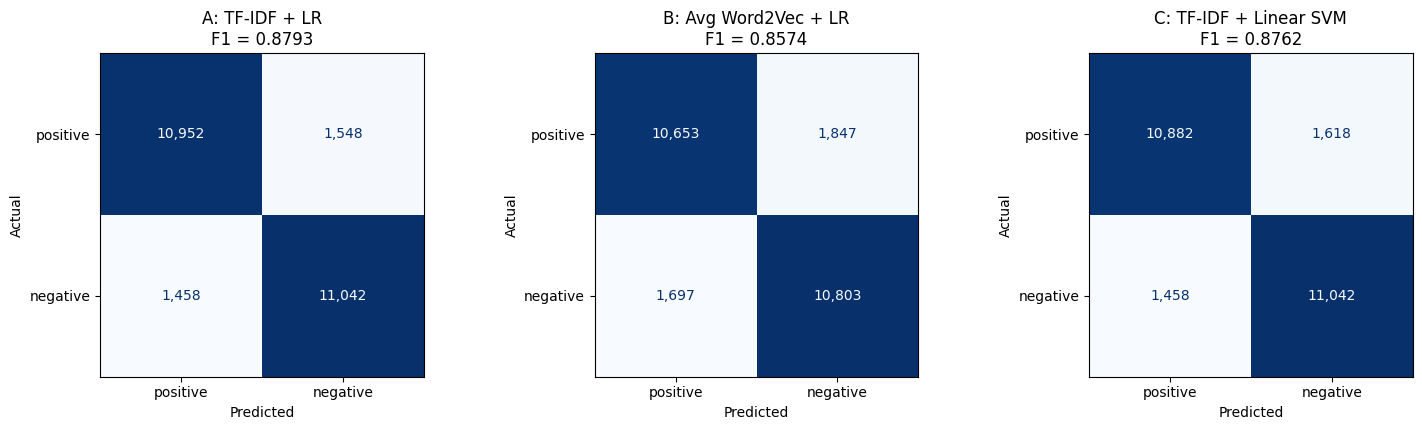

In [27]:
MODELS = {"A: TF-IDF + LR": run_A, "B: Avg Word2Vec + LR": run_B, "C: TF-IDF + Linear SVM": run_C}

fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.4))
for ax, (name, run) in zip(axes, MODELS.items()):
    cm = confusion_matrix(y_test, run["y_pred"], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(
        ax=ax, cmap="Blues", values_format=",d", colorbar=False)
    ax.set_title(f"{name}\nF1 = {run['row']['f1']:.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
fig.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
rows = []
for name, run in MODELS.items():
    tn, fp, fn, tp = confusion_matrix(y_test, run["y_pred"], labels=[0, 1]).ravel()
    rows.append({"model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn, **run["row"]})
pd.DataFrame(rows).set_index("model")[["TP", "FN", "FP", "TN", "accuracy", "precision", "recall", "f1"]].round(4)

,TP,FN,FP,TN,accuracy,precision,recall,f1
model,,,,,,,,
A: TF-IDF + LR,10952,1548,1458,11042,0.8798,0.8825,0.8762,0.8793
B: Avg Word2Vec + LR,10653,1847,1697,10803,0.8582,0.8626,0.8522,0.8574
C: TF-IDF + Linear SVM,10882,1618,1458,11042,0.8770,0.8818,0.8706,0.8762


In [29]:
print("Model A — classification report (test)")
print(classification_report(y_test, run_A["y_pred"], target_names=["negative", "positive"], digits=4))

Model A — classification report (test)
              precision    recall  f1-score   support

    negative     0.8770    0.8834    0.8802     12500
    positive     0.8825    0.8762    0.8793     12500

    accuracy                         0.8798     25000
   macro avg     0.8798    0.8798    0.8798     25000
weighted avg     0.8798    0.8798    0.8798     25000



> ✍️ **Tự trả lời:** Class nào bị nhầm nhiều nhất? Loại error nào chiếm nhiều (FP hay FN)? Metric nào phản ánh vấn đề đó?
>
> Pos bị đoán nhầm nhiều nhất (vì FN > FP). Metric phản ánh vấn đề này là Recall, vì Recall = TP / (TP + FN) nên khi FN cao thì Recall thấp, cho thấy model không nhận diện tốt các trường hợp positive.

## 10. Error analysis — Model A: TF-IDF + LR (Đề §21)

Chọn ngẫu nhiên (seed cố định) **3 correctly** + **3 incorrectly classified** từ test.
Mỗi review in kèm `P(pos)` và các feature đóng góp nhiều nhất vào $z$ để hỗ trợ phân tích.
Việc xác định nguyên nhân lỗi (negation, sarcasm, rare word, ...) ghi vào `error_analysis.md`.

In [30]:
proba_A = run_A["clf"].predict_proba(run_A["Xte"])[:, 1]
correct = np.flatnonzero(run_A["y_pred"] == y_test)
wrong = np.flatnonzero(run_A["y_pred"] != y_test)
print(f"Correct: {len(correct):,} | Incorrect: {len(wrong):,}")

rng = np.random.default_rng(SEED)
sample_correct = rng.choice(correct, 3, replace=False)
sample_wrong = rng.choice(wrong, 3, replace=False)


def show_example(i, max_chars=1500, top=8):
    text = pp.clean_text(X_test.iloc[i])
    c = contributions(run_A, X_test.iloc[i])
    print("=" * 100)
    print(f"test idx={i} | true={pp.LABEL_NAMES[y_test[i]]} | pred={pp.LABEL_NAMES[run_A['y_pred'][i]]}"
          f" | P(pos)={proba_A[i]:.3f} | n_tokens={test_df.loc[i, 'n_tokens']}")
    print("-" * 100)
    print(text[:max_chars] + (" ..." if len(text) > max_chars else ""))
    print("-" * 100)
    print("Đẩy về positive:", ", ".join(f"{f} ({v:+.3f})" for f, v in c.nlargest(top, "contribution")[["feature", "contribution"]].values))
    print("Đẩy về negative:", ", ".join(f"{f} ({v:+.3f})" for f, v in c.nsmallest(top, "contribution")[["feature", "contribution"]].values))

Correct: 21,994 | Incorrect: 3,006


In [31]:
print("##### 3 CORRECTLY CLASSIFIED #####")
for i in sample_correct:
    show_example(i)

##### 3 CORRECTLY CLASSIFIED #####
test idx=16321 | true=positive | pred=positive | P(pos)=0.970 | n_tokens=118
----------------------------------------------------------------------------------------------------
great movie. post-apocalyptic films kick ass. this one is no exception. kept up the pace and interest without a speck of dialogue (mainly through some good character development). the fight between reno and the hero was tight. i also liked the use of cave paintings and medieval-like weapons to show how primitive and savage mankind had become without their technology and guzzaline. the connection between the beginning and end was a little spacey, that is, i had a hard time understanding the distances between the hotel and the opening sequence. in sum, kick ass character progression, design, story without the cushion of dialogue, and most importantly, the always appreciated desolate scenery of a post-apocalyptic wasteland.
--------------------------------------------------------

In [32]:
print("##### 3 INCORRECTLY CLASSIFIED #####")
for i in sample_wrong:
    show_example(i)

##### 3 INCORRECTLY CLASSIFIED #####
test idx=2346 | true=negative | pred=positive | P(pos)=0.508 | n_tokens=266
----------------------------------------------------------------------------------------------------
on paper this movie has some chops: a street kid overcoming past trauma, rebuilding his life and succeeding when the world would have written him off. great stuff, everyone loves a happy ending. in the theater though, there were some omissions that left the movie dead inside. the dialog was hollow and uninteresting, the characters were almost cartoonish in their lack of dimension and complexity, and why did everyone need to be gay? i have nothing against homosexual themes or characters in a movie but when it's used in this fashion not only is is offensive to homosexuals, it trivializes the lifestyle and cheapens the movie. if the story works without this cheap trick it should have been cut. every character seemed to come out of the same cookie cutter form: each had one major 

In [33]:
# Bảng khung để copy sang error_analysis.md (cột Analysis tự điền)
print("| # | Text (rút gọn) | True | Predicted | P(pos) | Analysis |")
print("|---|---|---|---|---|---|")
for i in [*sample_correct, *sample_wrong]:
    snippet = pp.clean_text(X_test.iloc[i])[:150].replace("|", "/")
    print(f"| {i} | {snippet}... | {pp.LABEL_NAMES[y_test[i]]} | {pp.LABEL_NAMES[run_A['y_pred'][i]]} "
          f"| {proba_A[i]:.3f} | |")

| # | Text (rút gọn) | True | Predicted | P(pos) | Analysis |
|---|---|---|---|---|---|
| 16321 | great movie. post-apocalyptic films kick ass. this one is no exception. kept up the pace and interest without a speck of dialogue (mainly through some... | positive | positive | 0.970 | |
| 2195 | it only took one viewing of this dog, for me to say "never again!" it's so profoundly unmemorable that i had to read other people's reactions to it be... | negative | negative | 0.098 | |
| 19308 | this program is a favorite of our family, and we feel it must be released on dvd by seasons!!! the title of "promised land" is very apt, as it is a po... | positive | positive | 0.995 | |
| 2346 | on paper this movie has some chops: a street kid overcoming past trauma, rebuilding his life and succeeding when the world would have written him off.... | negative | positive | 0.508 | |
| 17654 | the only reason i decided to view this film is because of the great acting talents of karen sillas,(alyson haywo

**Gợi ý thêm (không bắt buộc):** các lỗi model "tự tin" nhất và các lỗi trên review ngắn nhất —
có thể chọn thay cho mẫu ngẫu nhiên nếu muốn ví dụ rõ hơn. Dùng `show_example(idx)` để xem chi tiết.

In [34]:
err = pd.DataFrame({"idx": wrong,
                    "true": [pp.LABEL_NAMES[v] for v in y_test[wrong]],
                    "P(pos)": proba_A[wrong].round(3),
                    "n_tokens": test_df.loc[wrong, "n_tokens"].to_numpy(),
                    "text": [pp.clean_text(t)[:150] for t in X_test.iloc[wrong]]})
err["confidence"] = (err["P(pos)"] - 0.5).abs()
display(err.nlargest(5, "confidence"))
display(err.nsmallest(5, "n_tokens"))

,idx,true,P(pos),n_tokens,text,confidence
1402,12061,negative,0.999,81,this movie was pure genius. john waters is brilliant. it is hilarious and i am not sick of it even after seeing it a...,0.499
421,3757,negative,0.998,263,"i went to see this 3 nights ago here in cork, ireland. it was the world premiere of it, in the tiny cinema in the tr...",0.498
461,4118,negative,0.998,61,this is definitely one of the best kung fu movies in the history of cinema. the screenplay is really well done (whic...,0.498
392,3553,negative,0.997,73,"this film has the language, the style and the attitude down ... plus greats rides from occy (a world champ) and the ...",0.497
691,6245,negative,0.997,409,mickey rourke hunts diane lane in elmore leonard's killshot it is not like mickey rourke ever really disappeared. he...,0.497


,idx,true,P(pos),n_tokens,text,confidence
995,8658,negative,0.931,8,"more suspenseful, more subtle, much, much more disturbing....",0.431
2513,21079,positive,0.358,21,for pure gothic vampire cheese nothing can compare to the subspecies films. i highly recommend each and every one of...,0.142
1660,14030,positive,0.468,22,"subject matter: cosmology, quantum physics and stephen hawking soundtrack: phillip glass have i died and gone to hea...",0.032
1883,16042,positive,0.444,24,"very intelligent language usage of ali, which you musn't miss! in one word: (eeh sentence...) wicked, so keep it rea...",0.056
1600,13590,positive,0.450,27,"a really realistic, sensible movie by ramgopal verma . no stupidity like songs as in other hindi movies. class actin...",0.050


# Error Analysis — LAB 04 (Đề §21)

**Model:** A — TF-IDF (unigram) + Logistic Regression · **Dataset:** IMDb test set
**Cách chọn mẫu:** ngẫu nhiên với seed = 42 (notebook mục 10)

## Bảng tổng hợp

| # | Text (rút gọn) | True | Predicted | P(pos) | Analysis |
|---|---|---|---|---|---|
| … | … | … | … | … | … |

## A. 3 mẫu phân loại đúng

### Mẫu 1 — idx = …
- **True / Predicted / P(pos):** … / … / …
- **Từ đẩy về positive:** …
- **Từ đẩy về negative:** …

> ✍️ **Tự trả lời:** Model đoán đúng nhờ những từ nào? Các từ đó có thật sự mang sentiment không, hay model đúng nhờ từ không liên quan (tên riêng, số, từ chung chung)?
>
> _(viết câu trả lời ở đây)_

### Mẫu 2 — idx = …
(lặp lại cấu trúc như Mẫu 1)

### Mẫu 3 — idx = …
(lặp lại cấu trúc như Mẫu 1)

## B. 3 mẫu phân loại sai

### Lỗi 1 — idx = …
- **True / Predicted / P(pos):** … / … / …
- **Từ đẩy về positive:** …
- **Từ đẩy về negative:** …

> ✍️ **Tự trả lời:** Lỗi này thuộc loại nào? (lexical ambiguity / negation / sarcasm / short text / rare word / domain-specific term / data noise / class imbalance — có thể nhiều hơn một loại)
>
> _(viết câu trả lời ở đây)_

> ✍️ **Tự trả lời:** Đoạn nào trong review là bằng chứng cho loại lỗi đó? Vì sao TF-IDF unigram không xử lý được?
>
> _(viết câu trả lời ở đây)_

### Lỗi 2 — idx = …
(lặp lại cấu trúc như Lỗi 1)

### Lỗi 3 — idx = …
(lặp lại cấu trúc như Lỗi 1)

## C. Tổng kết

> ✍️ **Tự trả lời:** Trong các lỗi đã xem, loại lỗi nào xuất hiện nhiều nhất? Điều đó có khớp với kết quả ở Experiment 4 (word order) và confusion matrix (§20) không?
>
> _(viết câu trả lời ở đây)_


### So sánh lỗi giữa Model A (TF-IDF) và Model B (Avg Word2Vec) — phần thêm, hỗ trợ §16

In [35]:
a_ok, b_ok = run_A["y_pred"] == y_test, run_B["y_pred"] == y_test
display(pd.Series({"A đúng, B sai": (a_ok & ~b_ok).sum(), "A sai, B đúng": (~a_ok & b_ok).sum(),
                   "cả hai sai": (~a_ok & ~b_ok).sum(), "cả hai đúng": (a_ok & b_ok).sum()}).to_frame("count"))

for title, mask in [("A đúng, B sai", a_ok & ~b_ok), ("A sai, B đúng", ~a_ok & b_ok)]:
    print(f"\n##### {title} — 2 review ngắn nhất #####")
    for i in test_df.loc[mask, "n_tokens"].nsmallest(2).index:
        print(f"[idx={i}, true={pp.LABEL_NAMES[y_test[i]]}] {pp.clean_text(X_test.iloc[i])[:400]}")

,count
"A đúng, B sai",1667
"A sai, B đúng",1129
cả hai sai,1877
cả hai đúng,20327



##### A đúng, B sai — 2 review ngắn nhất #####
[idx=41, true=negative] widow hires a psychopath as a handyman. sloppy film noir thriller which doesn't make much of its tension promising set-up. (3/10)
[idx=19774, true=positive] if you are french native, then you find this movie extremely funny. it's good, just good! can though imagine that subtitles or translations don't mean much in english.

##### A sai, B đúng — 2 review ngắn nhất #####
[idx=21079, true=positive] for pure gothic vampire cheese nothing can compare to the subspecies films. i highly recommend each and every one of them.
[idx=16042, true=positive] very intelligent language usage of ali, which you musn't miss! in one word: (eeh sentence...) wicked, so keep it real and pass it on!


## 11. Inspect model weights (Đề §22)

Với $z = \mathbf{w}^\top \mathbf{x} + b$: feature có $w_j > 0$ có xu hướng đẩy về `positive`,
$w_j < 0$ đẩy về `negative`.

Top positive features         Top negative features        
                 feature  weight               feature  weight
0                  great  10.289                 worst -16.416
1              excellent  10.071                 awful -12.508
2                      7   9.803                boring -11.076
3                perfect   9.366                 waste -11.041
4                   best   8.014                   bad  -9.815
5                  today   7.592                  poor  -9.652
6               favorite   7.566                 worse  -9.584
7              wonderful   7.462                poorly  -9.372
8                enjoyed   7.317                 fails  -8.890
9                      8   6.821              terrible  -8.236
10            refreshing   6.765        disappointment  -8.022
11               amazing   6.630                  mess  -7.721
12             brilliant   6.365               nothing  -7.666
13                 loved   6.313         unfortunately  -7.396
14                superb   6.221                 lacks  -7.237
15                highly   6.146              horrible  -7.170
16            definitely   6.059         disappointing  -7.026
17                  well   5.951                  dull  -6.863
18                   fun   5.897             pointless  -6.692
19                   job   5.897            ridiculous  -6.649

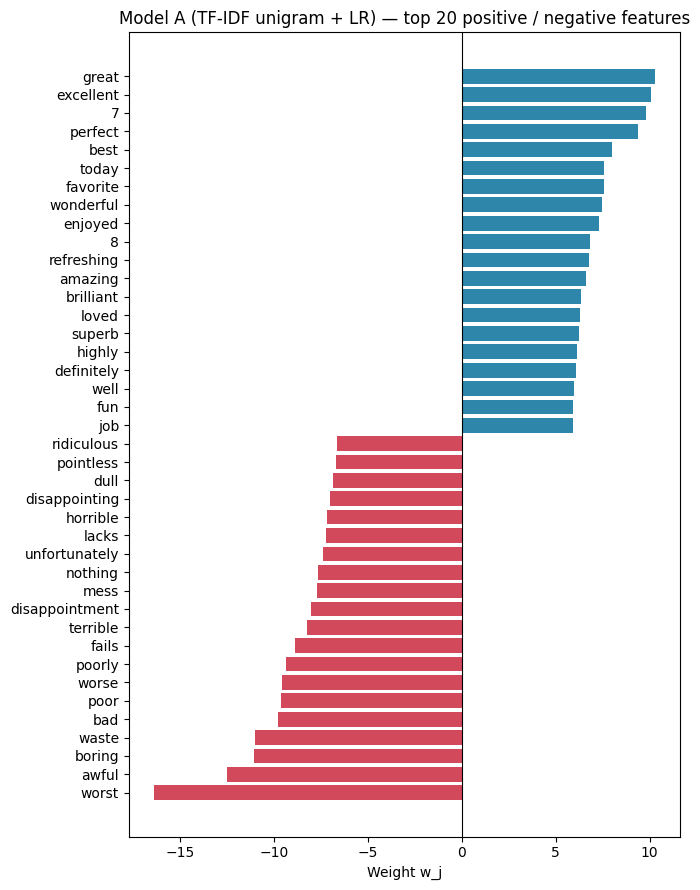

In [36]:
def top_features(run, k=20, only_bigrams=False):
    df = pd.DataFrame({"feature": feature_names(run), "weight": run["clf"].coef_.ravel()})
    if only_bigrams:
        df = df[df["feature"].str.contains(" ")]
    return df.nlargest(k, "weight").reset_index(drop=True), df.nsmallest(k, "weight").reset_index(drop=True)


top_pos, top_neg = top_features(run_A)
display(pd.concat({"Top positive features": top_pos, "Top negative features": top_neg}, axis=1).round(3))

data = pd.concat([top_pos, top_neg]).sort_values("weight")
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(data["feature"], data["weight"], color=np.where(data["weight"] > 0, "#2e86ab", "#d1495b"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Weight w_j")
ax.set_title("Model A (TF-IDF unigram + LR) — top 20 positive / negative features")
plt.tight_layout()
plt.show()

In [37]:
weight_of(run_A, ["excellent", "amazing", "terrible", "boring"]).round(4).to_frame("weight")

,weight
excellent,10.0712
amazing,6.6301
terrible,-8.2357
boring,-11.0763


In [38]:
bi_pos, bi_neg = top_features(run_bi, k=15, only_bigrams=True)
pd.concat({"Top positive bigrams": bi_pos, "Top negative bigrams": bi_neg}, axis=1).round(3)

Top positive bigrams         Top negative bigrams        
                feature  weight              feature  weight
0                  7 10  10.313            the worst -16.497
1              the best   9.439                 4 10 -10.394
2                 a bit   8.134               at all  -9.751
3                a must   8.127            than this  -8.217
4           better than   7.957            not worth  -8.127
5                 7 out   7.832             waste of  -7.810
6            well worth   7.580         the original  -7.713
7             very well   7.501              at best  -7.446
8                on dvd   7.310                 3 10  -7.093
9           my favorite   7.258             not even  -7.002
10                 is a   7.005             just not  -6.825
11         enjoyed this   7.003              way too  -6.501
12              this is   6.920          the problem  -6.305
13     definitely worth   6.819                4 out  -6.278
14             must see   6.637            with this  -6.042

> ✍️ **Tự trả lời:** Những feature này có thực sự có ý nghĩa đối với task không? (có feature nào lạ / phụ thuộc domain / nhiễu?)
>
> Các feature có trọng số cao đều có ý nghĩa với task, ví dụ "excellent", "great", "best" là các từ tích cực, còn "worst", "boring", "waste" là các từ tiêu cực. Tuy nhiên cũng có một số feature lạ hoặc phụ thuộc domain, ví dụ "movie" hay "film" là các từ chung chung, không mang nhiều ý nghĩa phân loại sentiment. Ngoài ra, một số từ như "not" hay "but" cũng có thể gây nhiễu nếu không được xử lý đúng cách trong ngữ cảnh.

## 12. Tổng hợp → `results.csv` (Đề §26 — deliverables)

Tất cả số liệu là trên **test set**; `val_f1` là F1 trên validation dùng để chọn `C`.

In [39]:
results = pd.DataFrame(RESULTS.values())
results.to_csv("results.csv", index=False)
results.round(4)

,experiment,representation,classifier,features,vocab_size,n_dims,best_C,train_time_s,val_f1,accuracy,precision,recall,f1
0,Exp2 baseline / Exp3-A / Exp5 unigram,TF-IDF,Logistic Regression,unigram,43077,43077,10,3.4913,0.9024,0.8798,0.8825,0.8762,0.8793
1,Exp3-B,Avg Word2Vec,Logistic Regression,skip-gram d=100,45311,100,1,49.0902,0.8682,0.8582,0.8626,0.8522,0.8574
2,Exp3-C,TF-IDF,Linear SVM,unigram,43077,43077,1,3.2257,0.8993,0.8770,0.8818,0.8706,0.8762
3,Exp5,TF-IDF,Logistic Regression,uni + bigram,363647,363647,100,9.8825,0.9167,0.9020,0.9012,0.9031,0.9021
4,Pred3 vocab size,TF-IDF,Logistic Regression,"unigram, max_features=500",500,500,10,2.8965,0.8414,0.8427,0.8331,0.8571,0.8450
5,Pred3 vocab size,TF-IDF,Logistic Regression,"unigram, max_features=2000",2000,2000,10,3.3055,0.8780,0.8706,0.8664,0.8764,0.8713
6,Pred3 vocab size,TF-IDF,Logistic Regression,"unigram, max_features=10000",10000,10000,10,3.7760,0.8982,0.8763,0.8793,0.8722,0.8758
7,Pred3 vocab size,TF-IDF,Logistic Regression,"unigram, full vocab, min_df=2 (baseline)",43077,43077,10,3.5633,0.9024,0.8798,0.8825,0.8762,0.8793
8,Pred3 vocab size,TF-IDF,Logistic Regression,"unigram, full vocab, min_df=1",73542,73542,10,3.4517,0.9027,0.8804,0.8823,0.8778,0.8801
9,Pred4 stopwords,TF-IDF,Logistic Regression,"unigram, bỏ stopwords",42768,42768,1,2.7639,0.8984,0.8794,0.8754,0.8847,0.8800


In [40]:
# Bảng Experiment 3 theo format của đề
show(run_A, run_B, run_C)[["representation", "classifier", "accuracy", "precision", "recall", "f1"]]

,representation,classifier,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,0.8798,0.8825,0.8762,0.8793
1,Avg Word2Vec,Logistic Regression,0.8582,0.8626,0.8522,0.8574
2,TF-IDF,Linear SVM,0.8770,0.8818,0.8706,0.8762
